In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import os
import kagglehub


In [2]:
path = kagglehub.dataset_download("patrickfleith/nasa-battery-dataset")
print(path)

C:\Users\Abhishek\.cache\kagglehub\datasets\patrickfleith\nasa-battery-dataset\versions\2


In [3]:
meta = pd.read_csv(os.path.join(path, 'cleaned_dataset', 'metadata.csv'))
meta.head()

,type,start_time,ambient_temperature,battery_id,test_id,uid,filename,Capacity,Re,Rct
0,discharge,[2010. 7. 21. 15. 0. ...,4,B0047,0,1,00001.csv,1.6743047446975208,NaN,NaN
1,impedance,[2010. 7. 21. 16. 53. ...,24,B0047,1,2,00002.csv,NaN,0.05605783343888099,0.20097016584458333
2,charge,[2010. 7. 21. 17. 25. ...,4,B0047,2,3,00003.csv,NaN,NaN,NaN
3,impedance,[2010 7 21 20 31 5],24,B0047,3,4,00004.csv,NaN,0.05319185850921101,0.16473399914864734
4,discharge,[2.0100e+03 7.0000e+00 2.1000e+01 2.1000e+01 2...,4,B0047,4,5,00005.csv,1.5243662105099023,NaN,NaN


In [4]:
meta[meta['battery_id'] == 'B0005'].sort_values('test_id')['type'].value_counts()

type
impedance    278
charge       170
discharge    168
Name: count, dtype: int64

In [5]:
rows = []
for b in ['B0005', 'B0006', 'B0007', 'B0018']:
    df_battery = meta[meta['battery_id'] == b].sort_values('test_id')
    cycle = 0
    for _, test in df_battery.iterrows():
        if test['type'] == 'impedance':
            continue
        data = pd.read_csv(os.path.join(path, 'cleaned_dataset', 'data', test['filename']))
        first = data[data['Time'] <= 1000]
        if test['type'] == 'charge' and data['Time'].iloc[-1] > 1000:  # skip the few broken short charge files
            ch = first
        if test['type'] == 'discharge':
            cycle += 1
            rows.append(['B' + str(int(b[1:])), cycle,
                         ch['Current_measured'].mean(), ch['Voltage_measured'].mean(), ch['Temperature_measured'].mean(),
                         first['Current_measured'].abs().mean(), first['Voltage_measured'].mean(), first['Temperature_measured'].mean(),
                         float(test['Capacity'])])

full = pd.DataFrame(rows, columns=['battery_id', 'cycle', 'chI', 'chV', 'chT', 'disI', 'disV', 'disT', 'BCt'])

In [6]:
full['SOH'] = 50 * full['BCt']  

In [7]:
eol = 1.5
for b in full['battery_id'].unique():
    battery = full[full['battery_id'] == b]
    eol_cycle = battery[battery['BCt'] < eol]['cycle'].min()
    full.loc[battery.index, 'RUL'] = (eol_cycle - battery['cycle']).clip(lower=0)
full['RUL'] = full['RUL'].astype(int)

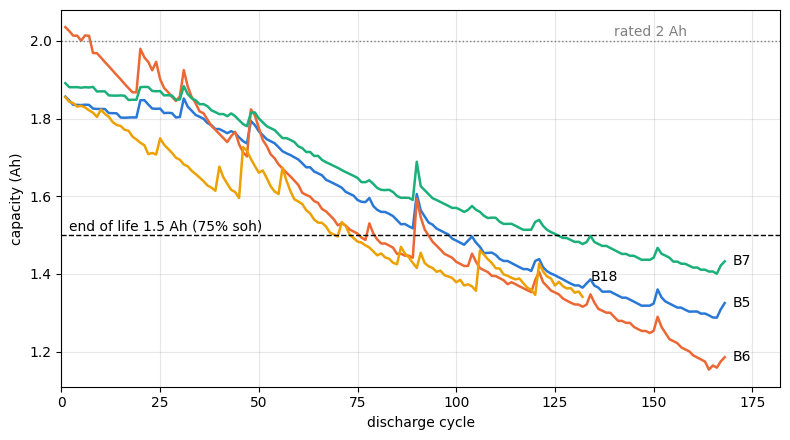

In [8]:
colors = {'B5': '#2a78d6', 'B6': '#eb6834', 'B7': '#1baf7a', 'B18': '#eda100'}  

label_up = {'B5': 0, 'B6': 0, 'B7': 0, 'B18': 0.05}
plt.figure(figsize=(8, 4.5))
for b in ['B5', 'B6', 'B7', 'B18']:
    battery = full[full['battery_id'] == b]
    plt.plot(battery['cycle'], battery['BCt'], color=colors[b], linewidth=1.8)
    plt.text(battery['cycle'].iloc[-1] + 2, battery['BCt'].iloc[-1] + label_up[b], b, va='center')
plt.axhline(2.0, color='grey', linewidth=1, linestyle=':')
plt.axhline(1.5, color='black', linewidth=1, linestyle='--')
plt.text(140, 2.005, 'rated 2 Ah', va='bottom', color='grey')
plt.text(2, 1.505, 'end of life 1.5 Ah (75% soh)', va='bottom')
plt.xlim(0, 182)
plt.xlabel('discharge cycle')
plt.ylabel('capacity (Ah)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/capacity-fade.png', bbox_inches='tight', dpi=150)
plt.show()

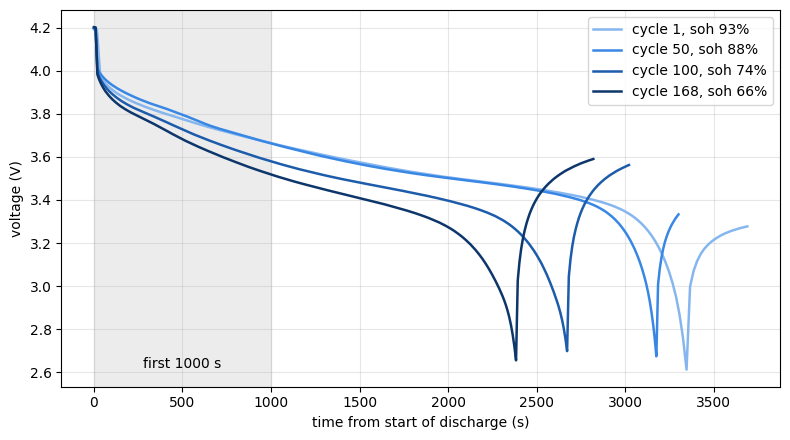

In [9]:
dis_tests = meta[(meta['battery_id'] == 'B0005') & (meta['type'] == 'discharge')].sort_values('test_id')
plt.figure(figsize=(8, 4.5))
for k, shade in zip([1, 50, 100, 168], ['#86b6ef', '#3987e5', '#1c5cab', '#0d366b']):
    data = pd.read_csv(os.path.join(path, 'cleaned_dataset', 'data', dis_tests['filename'].iloc[k - 1]))
    soh = 50 * float(dis_tests['Capacity'].iloc[k - 1])
    plt.plot(data['Time'], data['Voltage_measured'], color=shade, linewidth=1.8, label=f'cycle {k}, soh {soh:.0f}%')
plt.axvspan(0, 1000, color='grey', alpha=0.15)
plt.text(500, 2.62, 'first 1000 s', ha='center')
plt.xlabel('time from start of discharge (s)')
plt.ylabel('voltage (V)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/discharge-curves.png', bbox_inches='tight', dpi=150)
plt.show()

In [10]:
df = full[full['battery_id'] != 'B18'].reset_index(drop=True)

In [11]:
df.head()

,battery_id,cycle,chI,chV,chT,disI,disV,disT,BCt,SOH,RUL
0,B5,1,1.437081,4.148659,26.058157,1.939639,3.797753,28.161752,1.856487,92.824371,98
1,B5,2,1.485243,3.818951,27.410911,1.939567,3.802972,28.408474,1.846327,92.316362,97
2,B5,3,1.485171,3.821092,27.597455,1.939746,3.804758,28.394187,1.835349,91.767460,96
3,B5,4,1.485377,3.825682,27.522270,1.939181,3.806596,28.283929,1.835263,91.763126,95
4,B5,5,1.485155,3.823144,27.497313,1.939821,3.807330,28.144479,1.834646,91.732275,94


In [12]:
# 3 different batteries, 5,6,7, with cycle count, charge current, voltage and time with discharge current voltage time
# and battery capacity, state of health and remaining useful life

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 504 entries, 0 to 503
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   battery_id  504 non-null    object 
 1   cycle       504 non-null    int64  
 2   chI         504 non-null    float64
 3   chV         504 non-null    float64
 4   chT         504 non-null    float64
 5   disI        504 non-null    float64
 6   disV        504 non-null    float64
 7   disT        504 non-null    float64
 8   BCt         504 non-null    float64
 9   SOH         504 non-null    float64
 10  RUL         504 non-null    int64  
dtypes: float64(8), int64(2), object(1)
memory usage: 43.4+ KB


In [14]:
df['battery_id'].value_counts()

battery_id
B5    168
B6    168
B7    168
Name: count, dtype: int64

In [15]:
df['battery_id'] = df['battery_id'].astype('category')

In [16]:
df['battery_id'].cat.codes

0      0
1      0
2      0
3      0
4      0
      ..
499    2
500    2
501    2
502    2
503    2
Length: 504, dtype: int8

In [17]:
df['onehot_battery'] = df['battery_id'].cat.codes

In [18]:
df.head()

,battery_id,cycle,chI,chV,chT,disI,disV,disT,BCt,SOH,RUL,onehot_battery
0,B5,1,1.437081,4.148659,26.058157,1.939639,3.797753,28.161752,1.856487,92.824371,98,0
1,B5,2,1.485243,3.818951,27.410911,1.939567,3.802972,28.408474,1.846327,92.316362,97,0
2,B5,3,1.485171,3.821092,27.597455,1.939746,3.804758,28.394187,1.835349,91.767460,96,0
3,B5,4,1.485377,3.825682,27.522270,1.939181,3.806596,28.283929,1.835263,91.763126,95,0
4,B5,5,1.485155,3.823144,27.497313,1.939821,3.807330,28.144479,1.834646,91.732275,94,0


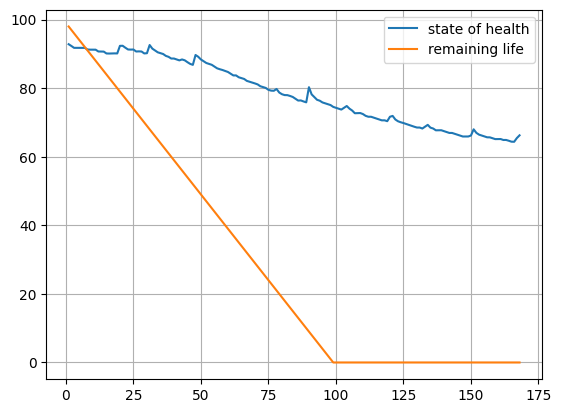

In [19]:
battery1= df[df['onehot_battery']==0]
plt.plot(battery1['cycle'], battery1['SOH'], label='state of health')
plt.plot(battery1['cycle'], battery1['RUL'], label='remaining life')
plt.grid()
plt.legend()
plt.savefig('images/battery-data-example.png', bbox_inches='tight', dpi=300)
plt.show()

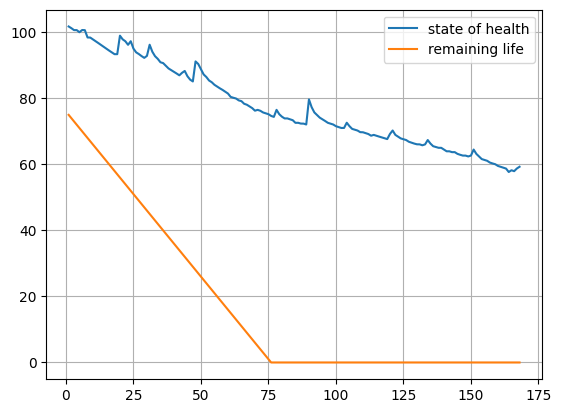

In [20]:
battery2= df[df['onehot_battery']==1]
plt.plot(battery2['cycle'], battery2['SOH'], label='state of health')
plt.plot(battery2['cycle'], battery2['RUL'], label='remaining life')
plt.grid()
plt.legend()
plt.show()

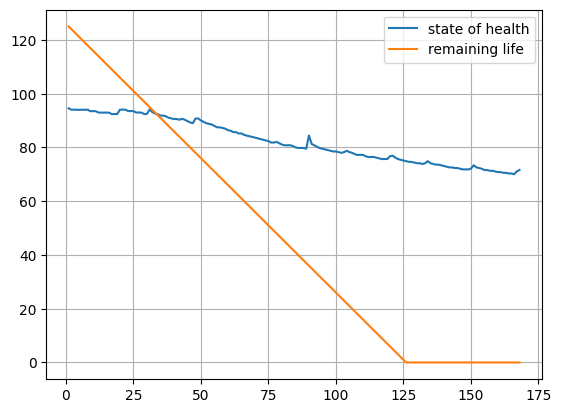

In [21]:
battery3= df[df['onehot_battery']==2]
plt.plot(battery3['cycle'], battery3['SOH'], label='state of health')
plt.plot(battery3['cycle'], battery3['RUL'], label='remaining life')
plt.grid()
plt.legend()
plt.show()

In [22]:
# first , we go for SOH

In [23]:
df.columns

Index(['battery_id', 'cycle', 'chI', 'chV', 'chT', 'disI', 'disV', 'disT',
       'BCt', 'SOH', 'RUL', 'onehot_battery'],
      dtype='object')

In [24]:
print((df['SOH'] - 50*df['BCt']).abs().max())
print((df['RUL'] + df['cycle']).groupby(df['onehot_battery']).nunique())

0.0
onehot_battery
0    70
1    93
2    43
dtype: int64


In [25]:
full.groupby('battery_id')[['chI', 'chV', 'chT', 'disI', 'disV', 'disT', 'SOH']].corr()['SOH'].unstack()[['chI', 'chV', 'chT', 'disI', 'disV', 'disT']].round(2)

,chI,chV,chT,disI,disV,disT
battery_id,,,,,,
B18,-0.07,-0.37,-0.19,0.97,0.98,0.15
B5,-0.13,-0.79,-0.26,-0.63,0.99,-0.56
B6,-0.14,-0.89,0.03,-0.73,0.99,-0.66
B7,-0.14,-0.75,-0.04,-0.66,0.99,-0.38


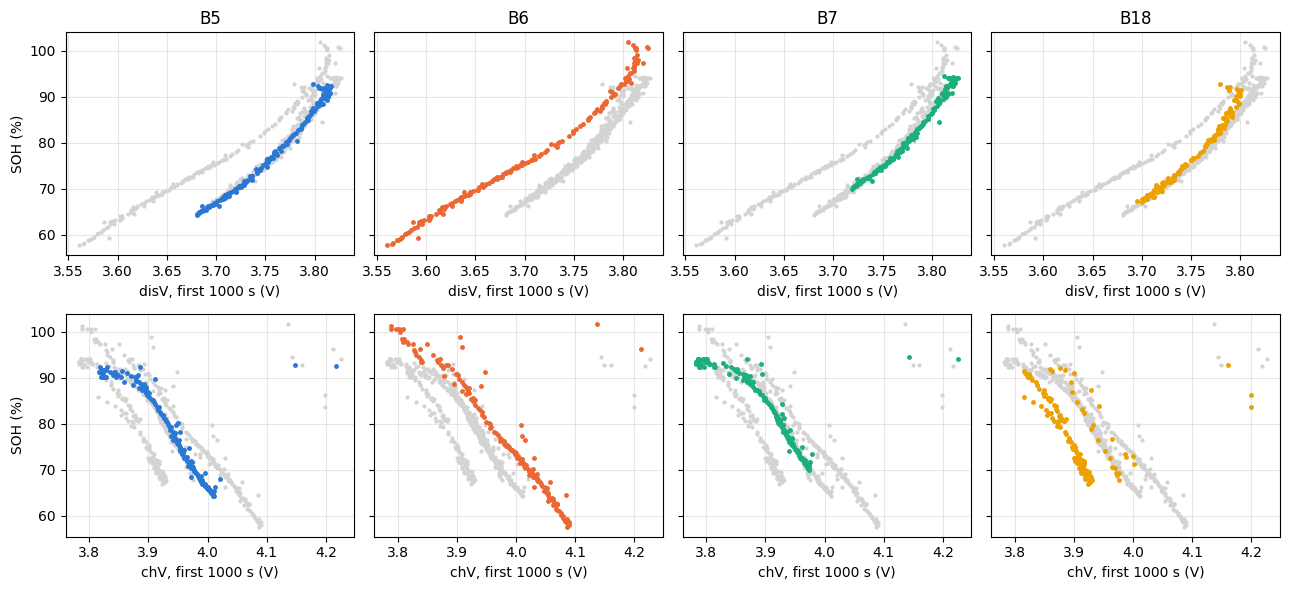

In [26]:
fig, axs = plt.subplots(2, 4, figsize=(13, 6), sharex='row', sharey=True)
for j, b in enumerate(['B5', 'B6', 'B7', 'B18']):
    battery = full[full['battery_id'] == b]
    others = full[full['battery_id'] != b]
    for i, col in enumerate(['disV', 'chV']):
        axs[i, j].plot(others[col], others['SOH'], '.', color='lightgrey', markersize=4)
        axs[i, j].plot(battery[col], battery['SOH'], '.', color=colors[b], markersize=5)
        axs[i, j].set_xlabel(col + ', first 1000 s (V)')
        axs[i, j].grid(alpha=0.3)
    axs[0, j].set_title(b)
axs[0, 0].set_ylabel('SOH (%)')
axs[1, 0].set_ylabel('SOH (%)')
plt.tight_layout()
plt.savefig('images/soh-vs-voltage.png', bbox_inches='tight', dpi=150)
plt.show()

In [27]:
features = ['disV']

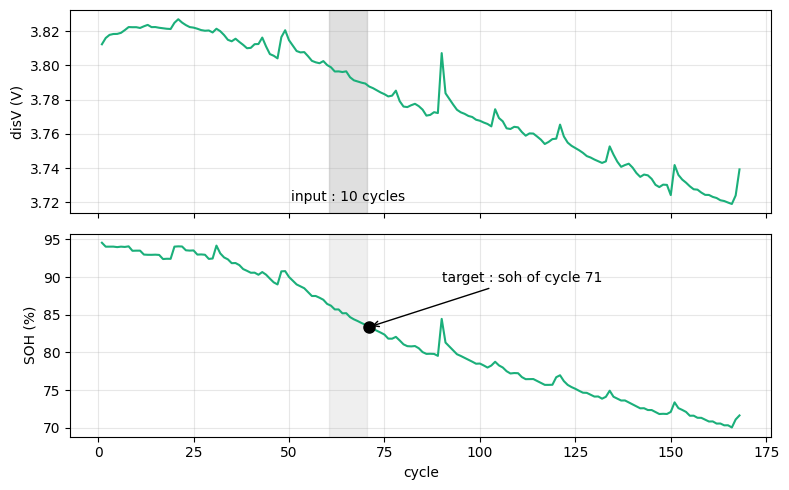

In [28]:
battery3 = full[full['battery_id'] == 'B7']
fig, axs = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
axs[0].plot(battery3['cycle'], battery3['disV'], color=colors['B7'], linewidth=1.5)
axs[1].plot(battery3['cycle'], battery3['SOH'], color=colors['B7'], linewidth=1.5)
axs[0].axvspan(60.5, 70.5, color='grey', alpha=0.25)
axs[1].axvspan(60.5, 70.5, color='grey', alpha=0.12)
axs[0].text(65.5, battery3['disV'].min(), 'input : 10 cycles', ha='center', va='bottom')
soh71 = battery3['SOH'].iloc[70]
axs[1].plot(71, soh71, 'o', color='black', markersize=8)
axs[1].annotate('target : soh of cycle 71', xy=(71, soh71), xytext=(90, soh71 + 6), arrowprops=dict(arrowstyle='->'))
axs[0].set_ylabel('disV (V)')
axs[1].set_ylabel('SOH (%)')
axs[1].set_xlabel('cycle')
for ax in axs:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/input-window.png', bbox_inches='tight', dpi=150)
plt.show()

In [29]:
df.head()

,battery_id,cycle,chI,chV,chT,disI,disV,disT,BCt,SOH,RUL,onehot_battery
0,B5,1,1.437081,4.148659,26.058157,1.939639,3.797753,28.161752,1.856487,92.824371,98,0
1,B5,2,1.485243,3.818951,27.410911,1.939567,3.802972,28.408474,1.846327,92.316362,97,0
2,B5,3,1.485171,3.821092,27.597455,1.939746,3.804758,28.394187,1.835349,91.767460,96,0
3,B5,4,1.485377,3.825682,27.522270,1.939181,3.806596,28.283929,1.835263,91.763126,95,0
4,B5,5,1.485155,3.823144,27.497313,1.939821,3.807330,28.144479,1.834646,91.732275,94,0


In [30]:
print(df['battery_id'].cat.categories)
train_b = [0, 1]
test_b = [2]

Index(['B5', 'B6', 'B7'], dtype='object')


In [31]:
from sklearn.preprocessing import StandardScaler

feature_scaler = StandardScaler()
soh_scaler = StandardScaler()
rul_scaler = StandardScaler()

train_mask = df['onehot_battery'].isin(train_b)
feature_scaler.fit(df.loc[train_mask, features])
df[features] = feature_scaler.transform(df[features])

soh_scaler.fit(df.loc[train_mask, ['SOH']])
rul_scaler.fit(df.loc[train_mask, ['RUL']])

df['SOH_scaled'] = soh_scaler.transform(df[['SOH']])
df['RUL_scaled'] = rul_scaler.transform(df[['RUL']])

In [32]:
seq_len = 10

In [33]:
seq_len = 10
seq, soh_list, rul_list, b_list = [], [], [], []

for b in range(0, 3):
    df_battery = df[df['onehot_battery'] == b]
    feat = df_battery[features].values
    soh_arr = df_battery['SOH_scaled'].values
    rul_arr = df_battery['RUL_scaled'].values

    for i in range(len(df_battery) - seq_len):
        seq.append(feat[i:i+seq_len])
        soh_list.append(soh_arr[i+seq_len])
        rul_list.append(rul_arr[i+seq_len])
        b_list.append(b)

In [34]:
seq = torch.FloatTensor(np.stack(seq))
soh = torch.FloatTensor(np.array(soh_list).reshape(-1, 1))
rul = torch.FloatTensor(np.array(rul_list).reshape(-1, 1))

train_idx = torch.tensor(np.isin(b_list, train_b))
test_idx = torch.tensor(np.isin(b_list, test_b))

In [35]:
seq = np.stack(seq)

In [36]:
seq.shape

(474, 10, 1)

In [37]:
seq[0]

array([[0.96693283],
       [1.0398641 ],
       [1.064825  ],
       [1.0905079 ],
       [1.1007726 ],
       [1.1268445 ],
       [1.1478809 ],
       [1.1718807 ],
       [1.1737683 ],
       [1.1813507 ]], dtype=float32)

In [38]:
soh = np.array(soh_list).reshape(-1,1)

In [39]:
soh[0]

array([1.18774434])

In [40]:
rul = np.array(rul_list).reshape(-1,1)

In [41]:
rul[0]

array([2.23264895])

In [42]:
seq=torch.FloatTensor(seq)

In [43]:
seq.shape

torch.Size([474, 10, 1])

In [44]:
soh = torch.FloatTensor(soh)

In [45]:
soh.shape

torch.Size([474, 1])

In [46]:
rul = torch.FloatTensor(rul)

In [47]:
rul.shape

torch.Size([474, 1])

In [48]:
train_idx = torch.tensor(np.isin(b_list, train_b))
test_idx = torch.tensor(np.isin(b_list, test_b))

xtr, xts = seq[train_idx], seq[test_idx]
ytr, yts = soh[train_idx], soh[test_idx]

In [49]:
xtr.shape

torch.Size([316, 10, 1])

In [50]:
xts.shape

torch.Size([158, 10, 1])

In [51]:
from torch.utils.data import TensorDataset, DataLoader

In [52]:
train_data = TensorDataset(xtr,ytr)
test_data = TensorDataset(xts,yts)

In [53]:
train_data

In [54]:
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

In [55]:
train_loader

In [56]:
test_loader

In [57]:
epochs = 100
num_layers = 1
hidden_size = 32
input_size=len(features)

In [58]:
lstm = nn.LSTM(input_size,hidden_size, num_layers,batch_first=True)

In [59]:
for x,y in train_loader:
    break

In [60]:
lstm_out, hidden_out = lstm(x)

In [61]:
lstm_out.shape

torch.Size([32, 10, 32])

In [62]:
lstm_out[:,-1,:].shape

torch.Size([32, 32])

In [63]:
class lstmmodel(nn.Module):
    def __init__(self, num_layers, hidden_size, input_size):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(hidden_size, 1)
        )

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        return self.fc(lstm_out[:, -1, :])

In [64]:
soh_model = lstmmodel(num_layers, hidden_size, input_size)

C:\Users\Abhishek\Vision course\dl-gpu-env\Lib\site-packages\torch\nn\modules\rnn.py:1009: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)


In [65]:
soh_model

lstmmodel(
  (lstm): LSTM(1, 32, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=32, out_features=1, bias=True)
  )
)

In [66]:
for param in soh_model.parameters():
    print(param.numel())

128
4096
128
128
32
1


In [67]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(soh_model.parameters(), lr=1e-3, weight_decay=1e-4)

In [68]:
torch.cuda.is_available()

True

In [69]:
soh_model.cuda()

lstmmodel(
  (lstm): LSTM(1, 32, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=32, out_features=1, bias=True)
  )
)

In [70]:
train_loss=[]
test_loss=[]
for epoch in range(epochs):
    soh_model.train()
    running = 0

    for x,y in train_loader:
        x = x.cuda()
        y = y.cuda()

        optimizer.zero_grad()
        pred = soh_model(x)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()

        running += loss.item() * len(x)
    train_loss.append(running / len(train_data))

    soh_model.eval()
    running = 0
    with torch.no_grad():
        for x,y in test_loader:
            x = x.cuda()
            y = y.cuda()

            pred = soh_model(x)
            running += criterion(pred,y).item() * len(x)
    test_loss.append(running / len(test_data))

    print(f"epoch: {epoch+1}, Training loss:{train_loss[-1]}, Test_loss:{test_loss[-1]}")

epoch: 1, Training loss:0.9684178301050693, Test_loss:0.5318372811697707
epoch: 2, Training loss:0.8678052478198763, Test_loss:0.5005900463725947
epoch: 3, Training loss:0.7706010884876493, Test_loss:0.45683763261082805
epoch: 4, Training loss:0.6428398814382432, Test_loss:0.38348584574989125
epoch: 5, Training loss:0.4414344878890846, Test_loss:0.2594328782980955
epoch: 6, Training loss:0.2410056551423254, Test_loss:0.14138389746599558
epoch: 7, Training loss:0.1590086259419405, Test_loss:0.1546789197416245
epoch: 8, Training loss:0.13342953775125213, Test_loss:0.09488100961699517
epoch: 9, Training loss:0.12386626042897188, Test_loss:0.039791647453874916
epoch: 10, Training loss:0.10859689323962489, Test_loss:0.05213310221752411
epoch: 11, Training loss:0.11035361565366576, Test_loss:0.054446434749502545
epoch: 12, Training loss:0.11808929120815254, Test_loss:0.04029766072908157
epoch: 13, Training loss:0.10848944662492487, Test_loss:0.049524050512457195
epoch: 14, Training loss:0.10

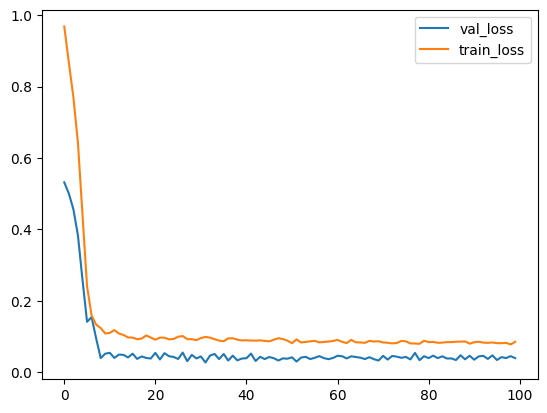

In [71]:
plt.plot(range(epochs), test_loss, label='val_loss')
plt.plot(range(epochs), train_loss, label='train_loss')
plt.legend()
plt.savefig('images/soh-training.png', bbox_inches='tight', dpi=300)
plt.show()

In [72]:
y_pred_scaled = []
y_true_scaled = []

soh_model.eval()
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.cuda(), y.cuda()
        pred = soh_model(x)
        y_true_scaled.append(y.cpu().detach().numpy())
        y_pred_scaled.append(pred.cpu().detach().numpy())

In [73]:
y_true_scaled = np.concatenate(y_true_scaled).flatten()
y_pred_scaled = np.concatenate(y_pred_scaled).flatten()

In [74]:
y_true = soh_scaler.inverse_transform(y_true_scaled.reshape(-1, 1)).flatten()
y_pred = soh_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()

In [75]:
# plain linear regression baseline on the same split
from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(xtr.reshape(len(xtr), -1).numpy(), ytr.numpy())
lin_pred = lin.predict(xts.reshape(len(xts), -1).numpy())
lin_pred = soh_scaler.inverse_transform(lin_pred.reshape(-1, 1)).flatten()  # back to soh %, same units as y_true

mean_pred = soh_scaler.inverse_transform([[ytr.numpy().mean()]])[0, 0]  # just guess the avg soh of b5, b6

print("lstm   RMSE:", np.sqrt(np.mean((y_true - y_pred)**2)), "MAE:", np.mean(np.abs(y_true - y_pred)))
print("linear RMSE:", np.sqrt(np.mean((y_true - lin_pred)**2)), "MAE:", np.mean(np.abs(y_true - lin_pred)))
print("mean   RMSE:", np.sqrt(np.mean((y_true - mean_pred)**2)))

lstm   RMSE: 2.2192223 MAE: 1.809996
linear RMSE: 4.178174 MAE: 3.8097763
mean   RMSE: 8.976108379343579


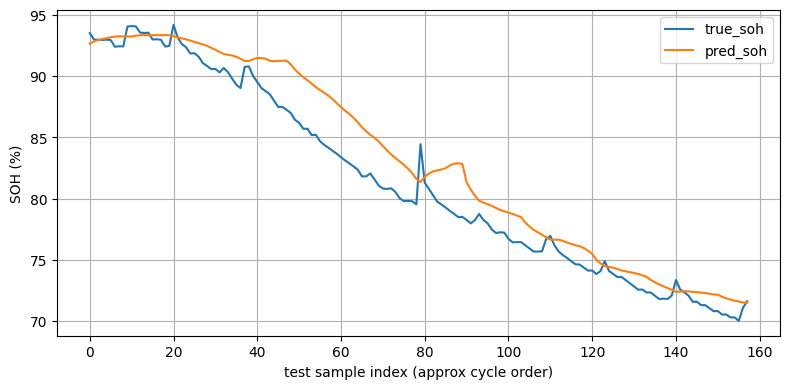

In [76]:
plt.figure(figsize=(8,4))
plt.plot(y_true, label="true_soh")
plt.plot(y_pred, label="pred_soh")
plt.xlabel("test sample index (approx cycle order)")
plt.ylabel("SOH (%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('images/soh-eval.png', bbox_inches='tight', dpi=300)
plt.show()

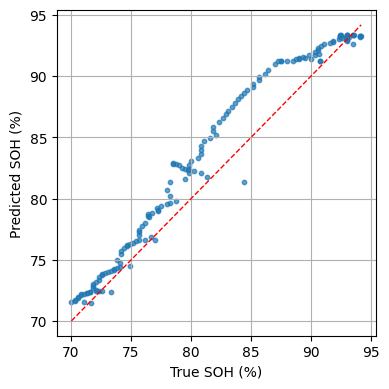

In [77]:
plt.figure(figsize=(4,4))
plt.scatter(y_true, y_pred, s=10, alpha=0.7)
lims = [min(y_true.min(), y_pred.min()),
        max(y_true.max(), y_pred.max())]
plt.plot(lims, lims, "r--", linewidth=1)  
plt.xlabel("True SOH (%)")
plt.ylabel("Predicted SOH (%)")
plt.grid(True)
plt.tight_layout()
plt.savefig('images/soh-true-vs-pred.png', bbox_inches='tight', dpi=300)
plt.show()

In [78]:
#now for rul

In [79]:
train_idx = torch.tensor(np.isin(b_list, train_b))
test_idx = torch.tensor(np.isin(b_list, test_b))

xtr, xts = seq[train_idx], seq[test_idx]
ytr, yts = rul[train_idx], rul[test_idx]

In [80]:
train_data = TensorDataset(xtr,ytr)
test_data = TensorDataset(xts,yts)

In [81]:
train_loader = DataLoader(train_data, batch_size=52, shuffle=True)
test_loader = DataLoader(test_data, batch_size = 13, shuffle = False )

In [82]:
epochs = 500
num_layers = 1
hidden_size = 150
input_size=len(features)

In [83]:
rul_model = lstmmodel(num_layers, hidden_size, input_size)

C:\Users\Abhishek\Vision course\dl-gpu-env\Lib\site-packages\torch\nn\modules\rnn.py:1009: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)


In [84]:
rul_model

lstmmodel(
  (lstm): LSTM(1, 150, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=150, out_features=1, bias=True)
  )
)

In [85]:
rul_model.cuda()

lstmmodel(
  (lstm): LSTM(1, 150, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=150, out_features=1, bias=True)
  )
)

In [86]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(rul_model.parameters(), lr=1e-3, weight_decay=1e-4)

In [87]:
train_loss=[]
test_loss=[]
for epoch in range(epochs):
    rul_model.train()
    running = 0

    for x,y in train_loader:
        x = x.cuda()
        y = y.cuda()

        optimizer.zero_grad()
        pred = rul_model(x)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()

        running += loss.item() * len(x)
    train_loss.append(running / len(train_data))

    rul_model.eval()
    running = 0
    with torch.no_grad():
        for x,y in test_loader:
            x = x.cuda()
            y = y.cuda()

            pred = rul_model(x)
            running += criterion(pred,y).item() * len(x)
    test_loss.append(running / len(test_data))

    print(f"epoch: {epoch+1}, Training loss:{train_loss[-1]}, Test_loss:{test_loss[-1]}")

epoch: 1, Training loss:0.7397834077666078, Test_loss:1.9706642263675038
epoch: 2, Training loss:0.5789904405799093, Test_loss:1.5636899368248032
epoch: 3, Training loss:0.34602755289289017, Test_loss:0.6235466274621461
epoch: 4, Training loss:0.13953436845088307, Test_loss:0.7457392398692384
epoch: 5, Training loss:0.12086829816616035, Test_loss:0.08428904613998683
epoch: 6, Training loss:0.09075648163126994, Test_loss:0.5299305664021757
epoch: 7, Training loss:0.06810586885372295, Test_loss:0.17966217390862824
epoch: 8, Training loss:0.04484950713341749, Test_loss:0.2555134484567974
epoch: 9, Training loss:0.045332005742607234, Test_loss:0.23051714356045558
epoch: 10, Training loss:0.04863306568770469, Test_loss:0.24481313408034133
epoch: 11, Training loss:0.045296534683696835, Test_loss:0.20286194130165291
epoch: 12, Training loss:0.05282906001976019, Test_loss:0.15215789277955324
epoch: 13, Training loss:0.04683523146506352, Test_loss:0.26279670494030927
epoch: 14, Training loss:0.

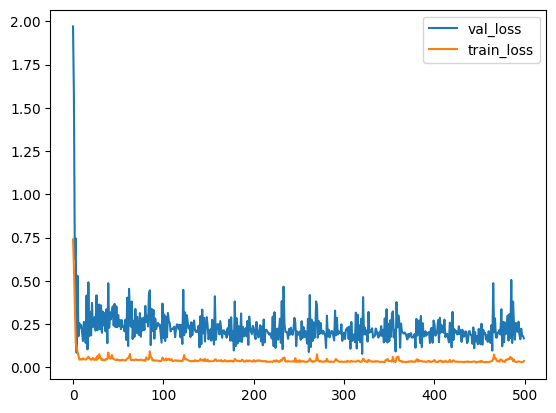

In [88]:
plt.plot(range(epochs), test_loss, label='val_loss')
plt.plot(range(epochs), train_loss, label='train_loss')
plt.legend()
plt.show()

In [89]:
y_pred_scaled = []
y_true_scaled = []

rul_model.eval()
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.cuda(), y.cuda()
        pred = rul_model(x)
        y_true_scaled.append(y.cpu().detach().numpy())
        y_pred_scaled.append(pred.cpu().detach().numpy())

In [90]:
y_true_scaled = np.concatenate(y_true_scaled).flatten()
y_pred_scaled = np.concatenate(y_pred_scaled).flatten()

In [91]:
y_true = rul_scaler.inverse_transform(y_true_scaled.reshape(-1, 1)).flatten()
y_pred = rul_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()

In [92]:
from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(xtr.reshape(len(xtr), -1).numpy(), ytr.numpy())
lin_pred = lin.predict(xts.reshape(len(xts), -1).numpy())
lin_pred = rul_scaler.inverse_transform(lin_pred.reshape(-1, 1)).flatten()  # back to cycles, same units as y_true

mean_pred = rul_scaler.inverse_transform([[ytr.numpy().mean()]])[0, 0]  # just guess the avg rul of b5, b6

print("lstm   RMSE:", np.sqrt(np.mean((y_true - y_pred)**2)), "MAE:", np.mean(np.abs(y_true - y_pred)))
print("linear RMSE:", np.sqrt(np.mean((y_true - lin_pred)**2)), "MAE:", np.mean(np.abs(y_true - lin_pred)))
print("mean   RMSE:", np.sqrt(np.mean((y_true - mean_pred)**2)))

lstm   RMSE: 11.930943 MAE: 9.53184
linear RMSE: 30.303034 MAE: 26.128826
mean   RMSE: 44.710735374997896


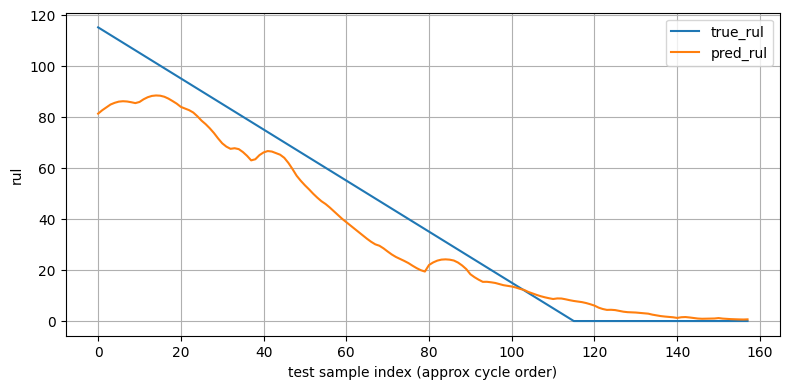

In [93]:
plt.figure(figsize=(8,4))
plt.plot(y_true, label="true_rul")
plt.plot(y_pred, label="pred_rul")
plt.xlabel("test sample index (approx cycle order)")
plt.ylabel("rul")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('images/rul-eval.png', bbox_inches='tight', dpi=300)
plt.show()

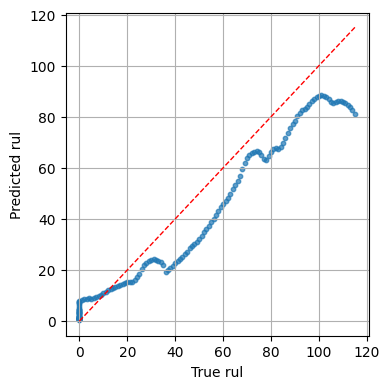

In [94]:
plt.figure(figsize=(4,4))
plt.scatter(y_true, y_pred, s=10, alpha=0.7)
lims = [min(y_true.min(), y_pred.min()),
        max(y_true.max(), y_pred.max())]
plt.plot(lims, lims, "r--", linewidth=1)  
plt.xlabel("True rul")
plt.ylabel("Predicted rul")
plt.grid(True)
plt.tight_layout()
plt.savefig('images/rul-true-vs-pred.png', bbox_inches='tight', dpi=300)
plt.show()

In [95]:
# final check : leave one battery out, on all 4 nasa batteries
# each battery takes one turn as the unseen test battery, train on the other 3, same lstm and epochs as above
# note : disV was picked after trying a few feature sets on these same 4 batteries, so a brand new battery may do a bit worse
from sklearn.linear_model import LinearRegression

cells = ['B5', 'B6', 'B7', 'B18']
results = []
for test_cell in cells:
    for target, hidden_size, epochs, bs in [('SOH', 32, 100, 32), ('RUL', 150, 500, 52)]:
        train_mask = full['battery_id'] != test_cell
        f_scaler = StandardScaler().fit(full.loc[train_mask, features])
        y_scaler = StandardScaler().fit(full.loc[train_mask, [target]])
        x_all = f_scaler.transform(full[features])
        y_all = y_scaler.transform(full[[target]]).flatten()

        seq, y_list, cell_list = [], [], []
        for b in cells:
            idx = np.where(full['battery_id'] == b)[0]
            for i in range(len(idx) - seq_len):
                seq.append(x_all[idx[i:i+seq_len]])
                y_list.append(y_all[idx[i+seq_len]])
                cell_list.append(b)
        seq = torch.FloatTensor(np.stack(seq))
        y_all = torch.FloatTensor(np.array(y_list).reshape(-1, 1))
        tr = torch.tensor(np.array(cell_list) != test_cell)
        ts = torch.tensor(np.array(cell_list) == test_cell)

        model = lstmmodel(1, hidden_size, len(features))
        model.cuda()
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
        loader = DataLoader(TensorDataset(seq[tr], y_all[tr]), batch_size=bs, shuffle=True)
        for epoch in range(epochs):
            model.train()
            for x, y in loader:
                x = x.cuda()
                y = y.cuda()
                optimizer.zero_grad()
                loss = criterion(model(x), y)
                loss.backward()
                optimizer.step()

        model.eval()
        with torch.no_grad():
            pred = model(seq[ts].cuda()).cpu().numpy()
        y_true = y_scaler.inverse_transform(y_all[ts].numpy()).flatten()
        y_pred = y_scaler.inverse_transform(pred).flatten()

        lin = LinearRegression()
        lin.fit(seq[tr].reshape(len(seq[tr]), -1).numpy(), y_all[tr].numpy())
        lin_pred = y_scaler.inverse_transform(lin.predict(seq[ts].reshape(len(seq[ts]), -1).numpy()).reshape(-1, 1)).flatten()
        mean_pred = y_scaler.inverse_transform([[y_all[tr].numpy().mean()]])[0, 0]

        results.append([test_cell, target,
                        np.sqrt(np.mean((y_true - y_pred)**2)),
                        np.sqrt(np.mean((y_true - lin_pred)**2)),
                        np.sqrt(np.mean((y_true - mean_pred)**2))])
        print(test_cell, target, 'done')

C:\Users\Abhishek\Vision course\dl-gpu-env\Lib\site-packages\torch\nn\modules\rnn.py:1009: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)


B5 SOH done


C:\Users\Abhishek\Vision course\dl-gpu-env\Lib\site-packages\torch\nn\modules\rnn.py:1009: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)


B5 RUL done


C:\Users\Abhishek\Vision course\dl-gpu-env\Lib\site-packages\torch\nn\modules\rnn.py:1009: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)


...

B7 RUL done


C:\Users\Abhishek\Vision course\dl-gpu-env\Lib\site-packages\torch\nn\modules\rnn.py:1009: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)


B18 SOH done


C:\Users\Abhishek\Vision course\dl-gpu-env\Lib\site-packages\torch\nn\modules\rnn.py:1009: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)


B18 RUL done


In [96]:
# rmse on each unseen battery. soh in %, rul in cycles
results = pd.DataFrame(results, columns=['test_battery', 'target', 'lstm', 'linear', 'mean'])
results.round(2)

,test_battery,target,lstm,linear,mean
0,B5,SOH,2.81,4.380000,9.18
1,B5,RUL,6.20,17.370001,29.13
2,B6,SOH,6.16,12.660000,11.90
3,B6,RUL,7.70,55.950001,24.95
4,B7,SOH,1.47,3.710000,8.99
5,B7,RUL,11.03,31.340000,45.39
6,B18,SOH,2.05,3.890000,7.11
7,B18,RUL,6.29,18.920000,22.75


In [97]:
results.groupby('target')[['lstm', 'linear', 'mean']].mean().round(2)

,lstm,linear,mean
target,,,
RUL,7.81,30.90,30.56
SOH,3.12,6.16,9.30


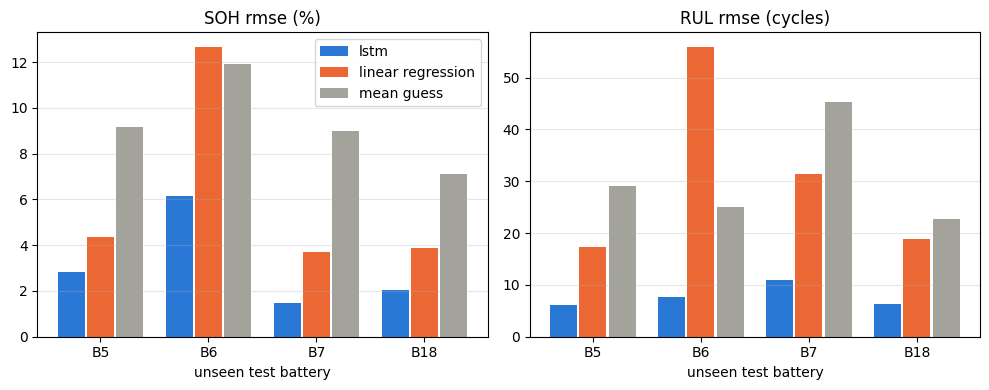

In [98]:
# rmse on each unseen battery, lower is better. grey = always guess the training average
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
x = np.arange(len(cells))
for ax, target, unit in zip(axs, ['SOH', 'RUL'], ['%', 'cycles']):
    r = results[results['target'] == target]
    ax.bar(x - 0.27, r['lstm'], 0.25, color='#2a78d6', label='lstm')
    ax.bar(x, r['linear'], 0.25, color='#eb6834', label='linear regression')
    ax.bar(x + 0.27, r['mean'], 0.25, color='#a3a29b', label='mean guess')
    ax.set_xticks(x)
    ax.set_xticklabels(cells)
    ax.set_xlabel('unseen test battery')
    ax.set_title(target + ' rmse (' + unit + ')')
    ax.grid(axis='y', alpha=0.3)
axs[0].legend()
plt.tight_layout()
plt.savefig('images/loco-results.png', bbox_inches='tight', dpi=150)
plt.show()